# **Exploratory Data Analysis: Global AI Workforce Displacement (2020–2026)**

Exploratory Data Analysis (EDA) helps us understand a dataset's structure, data quality, distributions, trends, and relationships before drawing conclusions.

**Dataset:** `ai_workforce_displacement_global_2020_2026.csv`

**Important:** The dataset's `data_source_notes` identifies it as research-calibrated synthetic data. Treat findings as patterns in this dataset, not as verified measurements of the real world.

### Import the necessary libraries

In [58]:
# Remove warning messages
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

### Import dataset

In [59]:
# Load the dataset
import pandas as pd
df = pd.read_csv(r"C:\Users\gauth\DataAnalytics\projects\DataSet\ai_workforce_displacement_global_2020_2026.csv")

### Display first 5 rows

In [60]:
df.head()

,record_id,country,iso3_code,region,income_group,year,quarter,quarter_label,industry_sector,sector_automation_risk_score,gdp_per_capita_usd,ai_adoption_index,pct_sector_workforce_displaced,pct_sector_workforce_new_roles_created,net_workforce_change_pct,ai_cited_layoff_announcements,ai_skill_wage_premium_pct,pct_workforce_female,pct_displaced_roles_female,reskilling_programs_count,govt_ai_policy_score_1_to_10,ai_tool_adoption_pct,data_source_notes
0,1,United States,USA,North America,High Income,2020,1,2020-Q1,Technology & Software,0.382,63514,0.830,0.0406,0.0348,-0.0058,32,0.311,0.28,0.275,52,6.4,0.280,Research-calibrated synthetic data. Grounded i...
1,2,United States,USA,North America,High Income,2020,1,2020-Q1,Finance & Banking,0.608,63514,0.817,0.0517,0.0423,-0.0094,51,0.304,0.48,0.511,39,6.5,0.559,Research-calibrated synthetic data. Grounded i...
2,3,United States,USA,North America,High Income,2020,1,2020-Q1,Healthcare & Life Sciences,0.198,63514,0.816,0.0176,0.0168,-0.0008,4,0.278,0.72,0.707,37,6.8,0.202,Research-calibrated synthetic data. Grounded i...
3,4,United States,USA,North America,High Income,2020,1,2020-Q1,Manufacturing & Industry,0.720,63514,0.818,0.0924,0.0642,-0.0282,47,0.268,0.29,0.310,50,6.8,0.655,Research-calibrated synthetic data. Grounded i...
4,5,United States,USA,North America,High Income,2020,1,2020-Q1,Retail & E-Commerce,0.676,63514,0.828,0.0667,0.0374,-0.0293,31,0.313,0.54,0.547,37,6.2,0.542,Research-calibrated synthetic data. Grounded i...


### Display the last 5 rows of the dataset

In [61]:
df.tail()

,record_id,country,iso3_code,region,income_group,year,quarter,quarter_label,industry_sector,sector_automation_risk_score,gdp_per_capita_usd,ai_adoption_index,pct_sector_workforce_displaced,pct_sector_workforce_new_roles_created,net_workforce_change_pct,ai_cited_layoff_announcements,ai_skill_wage_premium_pct,pct_workforce_female,pct_displaced_roles_female,reskilling_programs_count,govt_ai_policy_score_1_to_10,ai_tool_adoption_pct,data_source_notes
20795,20796,Zambia,ZMB,Africa,Lower Middle Income,2026,2,2026-Q2,Education & Research,0.308,1467,0.703,0.0218,0.0056,-0.0162,29,0.450,0.58,0.651,16,3.5,0.184,Research-calibrated synthetic data. Grounded i...
20796,20797,Zambia,ZMB,Africa,Lower Middle Income,2026,2,2026-Q2,Transportation & Logistics,0.675,1467,0.711,0.0534,0.0205,-0.0329,126,0.476,0.22,0.235,15,4.2,0.457,Research-calibrated synthetic data. Grounded i...
20797,20798,Zambia,ZMB,Africa,Lower Middle Income,2026,2,2026-Q2,Media & Communications,0.516,1467,0.709,0.0505,0.0154,-0.0351,131,0.446,0.46,0.482,17,4.3,0.419,Research-calibrated synthetic data. Grounded i...
20798,20799,Zambia,ZMB,Africa,Lower Middle Income,2026,2,2026-Q2,Administrative & Clerical,0.801,1467,0.702,0.0914,0.0260,-0.0654,476,0.499,0.79,0.950,14,4.2,0.459,Research-calibrated synthetic data. Grounded i...
20799,20800,Zambia,ZMB,Africa,Lower Middle Income,2026,2,2026-Q2,Energy & Utilities,0.440,1467,0.718,0.0376,0.0160,-0.0216,67,0.490,0.26,0.270,12,4.1,0.377,Research-calibrated synthetic data. Grounded i...


### Data cleaning

In [62]:
# Check missing values in every column
print(df.isna().sum())

record_id                                 0
country                                   0
iso3_code                                 0
region                                    0
income_group                              0
year                                      0
quarter                                   0
quarter_label                             0
industry_sector                           0
sector_automation_risk_score              0
gdp_per_capita_usd                        0
ai_adoption_index                         0
pct_sector_workforce_displaced            0
pct_sector_workforce_new_roles_created    0
net_workforce_change_pct                  0
ai_cited_layoff_announcements             0
ai_skill_wage_premium_pct                 0
pct_workforce_female                      0
pct_displaced_roles_female                0
reskilling_programs_count                 0
govt_ai_policy_score_1_to_10              0
ai_tool_adoption_pct                      0
data_source_notes               

### Check duplicate rows

In [63]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### Remove duplicate rows

In [64]:
# Remove duplicate rows, if any
df.drop_duplicates(inplace=True)
print("Shape after removing duplicate rows:", df.shape)

Shape after removing duplicate rows: (20800, 23)


### Check the data types

In [65]:
# Check the data types of all columns
print(df.dtypes)

record_id                                   int64
country                                       str
iso3_code                                     str
region                                        str
income_group                                  str
year                                        int64
quarter                                     int64
quarter_label                                 str
industry_sector                               str
sector_automation_risk_score              float64
gdp_per_capita_usd                          int64
ai_adoption_index                         float64
pct_sector_workforce_displaced            float64
pct_sector_workforce_new_roles_created    float64
net_workforce_change_pct                  float64
ai_cited_layoff_announcements               int64
ai_skill_wage_premium_pct                 float64
pct_workforce_female                      float64
pct_displaced_roles_female                float64
reskilling_programs_count                   int64


### Check basic statistical information

In [66]:
# Display descriptive statistics for numeric columns
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
record_id,20800.0,10400.500000,6004.587135,1.0000,5200.7500,10400.5000,15600.2500,20800.0000
year,20800.0,2022.769231,1.887406,2020.0000,2021.0000,2023.0000,2024.0000,2026.0000
quarter,20800.0,2.423077,1.115411,1.0000,1.0000,2.0000,3.0000,4.0000
sector_automation_risk_score,20800.0,0.537881,0.190345,0.1510,0.3790,0.5800,0.6980,0.8550
gdp_per_capita_usd,20800.0,21003.330769,22048.862955,879.0000,3456.5000,10635.0000,40528.5000,99074.0000
ai_adoption_index,20800.0,0.692148,0.161194,0.1690,0.5910,0.7200,0.8210,0.9630
pct_sector_workforce_displaced,20800.0,0.056155,0.044811,0.0018,0.0233,0.0434,0.0749,0.3000
pct_sector_workforce_new_roles_created,20800.0,0.035631,0.036586,0.0003,0.0098,0.0219,0.0494,0.2791
net_workforce_change_pct,20800.0,-0.020524,0.015327,-0.1403,-0.0282,-0.0164,-0.0091,-0.0003
ai_cited_layoff_announcements,20800.0,88.346538,85.198076,0.0000,24.0000,63.0000,126.0000,603.0000


### Check the dataset information

In [67]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20800 entries, 0 to 20799
Data columns (total 23 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   record_id                               20800 non-null  int64  
 1   country                                 20800 non-null  str    
 2   iso3_code                               20800 non-null  str    
 3   region                                  20800 non-null  str    
 4   income_group                            20800 non-null  str    
 5   year                                    20800 non-null  int64  
 6   quarter                                 20800 non-null  int64  
 7   quarter_label                           20800 non-null  str    
 8   industry_sector                         20800 non-null  str    
 9   sector_automation_risk_score            20800 non-null  float64
 10  gdp_per_capita_usd                      20800 non-null  int64  
 11  

### Clean column names

In [68]:
# Standardize column names
df.columns = (
    df.columns.str.strip()
              .str.lower()
              .str.replace(r'[^a-z0-9]+', '_', regex=True)
              .str.strip('_')
)
print(df.columns.tolist())

['record_id', 'country', 'iso3_code', 'region', 'income_group', 'year', 'quarter', 'quarter_label', 'industry_sector', 'sector_automation_risk_score', 'gdp_per_capita_usd', 'ai_adoption_index', 'pct_sector_workforce_displaced', 'pct_sector_workforce_new_roles_created', 'net_workforce_change_pct', 'ai_cited_layoff_announcements', 'ai_skill_wage_premium_pct', 'pct_workforce_female', 'pct_displaced_roles_female', 'reskilling_programs_count', 'govt_ai_policy_score_1_to_10', 'ai_tool_adoption_pct', 'data_source_notes']


### Check data types again

In [69]:
print(df.dtypes)

record_id                                   int64
country                                       str
iso3_code                                     str
region                                        str
income_group                                  str
year                                        int64
quarter                                     int64
quarter_label                                 str
industry_sector                               str
sector_automation_risk_score              float64
gdp_per_capita_usd                          int64
ai_adoption_index                         float64
pct_sector_workforce_displaced            float64
pct_sector_workforce_new_roles_created    float64
net_workforce_change_pct                  float64
ai_cited_layoff_announcements               int64
ai_skill_wage_premium_pct                 float64
pct_workforce_female                      float64
pct_displaced_roles_female                float64
reskilling_programs_count                   int64


### Handle missing values

In [70]:
# Missing-value count and percentage
missing_summary = pd.DataFrame({
    'Missing_Count': df.isna().sum(),
    'Missing_Percentage': (df.isna().mean() * 100).round(2)
})
display(missing_summary.sort_values('Missing_Count', ascending=False))

,Missing_Count,Missing_Percentage
record_id,0,0.0
country,0,0.0
iso3_code,0,0.0
region,0,0.0
income_group,0,0.0
year,0,0.0
quarter,0,0.0
quarter_label,0,0.0
industry_sector,0,0.0
sector_automation_risk_score,0,0.0


### Check unique values in categorical columns

In [71]:
# Review the unique values in categorical columns
for column in df.select_dtypes(include='object').columns:
    print(f"\\n{column}: {df[column].nunique()} unique values")
    print(df[column].value_counts(dropna=False).head(10))

\ncountry: 80 unique values
country
United States     260
China             260
Germany           260
United Kingdom    260
Japan             260
France            260
India             260
Canada            260
South Korea       260
Australia         260
Name: count, dtype: int64
\niso3_code: 80 unique values
iso3_code
USA    260
CHN    260
DEU    260
GBR    260
JPN    260
FRA    260
IND    260
CAN    260
KOR    260
AUS    260
Name: count, dtype: int64
\nregion: 12 unique values
region
Europe            5200
Latin America     3380
Africa            3380
Southeast Asia    2080
Middle East       1820
East Asia         1300
South Asia        1300
North America      520
Oceania            520
Europe/Asia        520
Name: count, dtype: int64
\nincome_group: 4 unique values
income_group
High Income            8060
Lower Middle Income    6240
Upper Middle Income    5720
Low Income              780
Name: count, dtype: int64
\nquarter_label: 26 unique values
quarter_label
2020-Q1    800
2020-Q

### Check numeric ranges and possible outliers

In [72]:
# Inspect numeric ranges for unusual values
display(df.select_dtypes(include=np.number).describe().T)

,count,mean,std,min,25%,50%,75%,max
record_id,20800.0,10400.500000,6004.587135,1.0000,5200.7500,10400.5000,15600.2500,20800.0000
year,20800.0,2022.769231,1.887406,2020.0000,2021.0000,2023.0000,2024.0000,2026.0000
quarter,20800.0,2.423077,1.115411,1.0000,1.0000,2.0000,3.0000,4.0000
sector_automation_risk_score,20800.0,0.537881,0.190345,0.1510,0.3790,0.5800,0.6980,0.8550
gdp_per_capita_usd,20800.0,21003.330769,22048.862955,879.0000,3456.5000,10635.0000,40528.5000,99074.0000
ai_adoption_index,20800.0,0.692148,0.161194,0.1690,0.5910,0.7200,0.8210,0.9630
pct_sector_workforce_displaced,20800.0,0.056155,0.044811,0.0018,0.0233,0.0434,0.0749,0.3000
pct_sector_workforce_new_roles_created,20800.0,0.035631,0.036586,0.0003,0.0098,0.0219,0.0494,0.2791
net_workforce_change_pct,20800.0,-0.020524,0.015327,-0.1403,-0.0282,-0.0164,-0.0091,-0.0003
ai_cited_layoff_announcements,20800.0,88.346538,85.198076,0.0000,24.0000,63.0000,126.0000,603.0000


## Data Understanding

In [73]:
# Basic information about the dataset
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
df.info()

Dataset shape: (20800, 23)
Number of rows: 20800
Number of columns: 23
<class 'pandas.DataFrame'>
RangeIndex: 20800 entries, 0 to 20799
Data columns (total 23 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   record_id                               20800 non-null  int64  
 1   country                                 20800 non-null  str    
 2   iso3_code                               20800 non-null  str    
 3   region                                  20800 non-null  str    
 4   income_group                            20800 non-null  str    
 5   year                                    20800 non-null  int64  
 6   quarter                                 20800 non-null  int64  
 7   quarter_label                           20800 non-null  str    
 8   industry_sector                         20800 non-null  str    
 9   sector_automation_risk_score            20800 non-null  float64
 10

In [74]:
# Summary statistics
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
record_id,20800.0,NaN,NaN,NaN,10400.5,6004.587135,1.0,5200.75,10400.5,15600.25,20800.0
country,20800,80,United States,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
iso3_code,20800,80,USA,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,20800,12,Europe,5200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_group,20800,4,High Income,8060,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,20800.0,NaN,NaN,NaN,2022.769231,1.887406,2020.0,2021.0,2023.0,2024.0,2026.0
quarter,20800.0,NaN,NaN,NaN,2.423077,1.115411,1.0,1.0,2.0,3.0,4.0
quarter_label,20800,26,2020-Q1,800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry_sector,20800,10,Technology & Software,2080,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sector_automation_risk_score,20800.0,NaN,NaN,NaN,0.537881,0.190345,0.151,0.379,0.58,0.698,0.855


### Questions

1. What are the dimensions, data types, and basic structure of the dataset?

2. Which 10 countries have the highest average percentage of sector workforce displaced?

3. What is the average workforce displacement percentage for each industry sector?

4. Which regions have the highest average AI adoption index?

5. Which industry sectors have the highest average automation risk score?

6. How many records belong to each income group, and what percentage of the dataset does each represent?

7. What is the average percentage of new roles created for each industry sector?

8. Which countries have an average net workforce change below zero?

9. Which country-industry records have high workforce displacement but also high new-role creation?

10. For each region, what is the most common industry sector?

11. What are the mean, median, standard deviation, minimum, and maximum values of workforce displacement percentage?

12. What are the 25th, 50th, and 75th percentiles of the sector automation risk score?

13. What percentage of records have negative net workforce change?

14. What percentage of records have workforce displacement above the dataset average?

15. Which sector automation risk scores are statistical outliers using the IQR method?

16. What is the distribution of records across industry sectors? Visualize it using a pie chart.

17. Which 10 countries have the highest average workforce displacement? Visualize them using a bar chart.

18. How does average workforce displacement change across years? Visualize the trend using a line chart.

19. Which industry sectors have the highest average AI adoption index? Visualize the top 10 using a bar chart.

20. What is the relationship between automation risk and workforce displacement? Visualize it using a scatter plot.

21. Is there a relationship between AI adoption index and AI tool adoption percentage? Calculate the correlation and visualize it with a regression plot.

22. How does workforce displacement vary across income groups? Use a boxplot.

23. How does net workforce change vary across regions? Use a boxplot.

24. What is the correlation between the major numerical variables? Create a correlation heatmap.

25. How do workforce displacement, new-role creation, and net workforce change change over time by quarter?

26. Is higher AI adoption associated with higher workforce displacement?

27. Is a higher automation risk score associated with lower net workforce change?

28. Which industry sectors have the highest automation risk and lowest net workforce change?

29. Which country-industry groups have both high workforce displacement and high AI-cited layoff announcements?

30. Can we create an overall workforce disruption classification using displacement, automation risk, net workforce change, and new-role creation?

In [75]:
# Q1. What are the dimensions, data types, and basic structure of the dataset?
print("Dataset shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
print("\\nData types:")
print(df.dtypes)
print("\\nDataset information:")
df.info()

Dataset shape: (20800, 23)
\nColumn names:
['record_id', 'country', 'iso3_code', 'region', 'income_group', 'year', 'quarter', 'quarter_label', 'industry_sector', 'sector_automation_risk_score', 'gdp_per_capita_usd', 'ai_adoption_index', 'pct_sector_workforce_displaced', 'pct_sector_workforce_new_roles_created', 'net_workforce_change_pct', 'ai_cited_layoff_announcements', 'ai_skill_wage_premium_pct', 'pct_workforce_female', 'pct_displaced_roles_female', 'reskilling_programs_count', 'govt_ai_policy_score_1_to_10', 'ai_tool_adoption_pct', 'data_source_notes']
\nData types:
record_id                                   int64
country                                       str
iso3_code                                     str
region                                        str
income_group                                  str
year                                        int64
quarter                                     int64
quarter_label                                 str
industry_sector        

In [76]:
# Q2. Which 10 countries have the highest average percentage of sector workforce displaced?
result = (
    df.groupby('country')['pct_sector_workforce_displaced']
      .mean()
      .sort_values(ascending=False)
      .head(10)
)
print(result)

country
Singapore        0.106867
Denmark          0.104123
United States    0.103910
Finland          0.103638
Sweden           0.103595
Switzerland      0.103151
Norway           0.102813
Israel           0.102085
Netherlands      0.101300
Hong Kong        0.101117
Name: pct_sector_workforce_displaced, dtype: float64


In [77]:
# Q3. What is the average workforce displacement percentage for each industry sector?
result = (
    df.groupby('industry_sector')['pct_sector_workforce_displaced']
      .mean()
      .sort_values(ascending=False) * 100
)
result = result.round(2)
display(result.rename('Average Workforce Displaced (%)'))

industry_sector
Administrative & Clerical     9.20
Manufacturing & Industry      7.94
Retail & E-Commerce           7.31
Transportation & Logistics    6.85
Finance & Banking             6.03
Media & Communications        5.41
Technology & Software         4.60
Energy & Utilities            4.20
Education & Research          2.52
Healthcare & Life Sciences    2.09
Name: Average Workforce Displaced (%), dtype: float64

In [78]:
# Q4. Which regions have the highest average AI adoption index?
result = (
    df.groupby('region')['ai_adoption_index']
      .mean()
      .sort_values(ascending=False)
)
print(result)

region
North America         0.863188
East Asia             0.848202
Oceania               0.827458
Europe                0.796663
Middle East           0.735563
Europe/Asia           0.698483
Southeast Asia        0.662900
Latin America         0.641559
Central Asia          0.609708
Middle East/Africa    0.574108
South Asia            0.570106
Africa                0.537141
Name: ai_adoption_index, dtype: float64


In [79]:
# Q5. Which industry sectors have the highest average automation risk score?
result = (
    df.groupby('industry_sector')['sector_automation_risk_score']
      .mean()
      .sort_values(ascending=False)
)
print(result)

industry_sector
Administrative & Clerical     0.789742
Manufacturing & Industry      0.739386
Retail & E-Commerce           0.689231
Transportation & Logistics    0.680379
Finance & Banking             0.610245
Media & Communications        0.550444
Energy & Utilities            0.449988
Technology & Software         0.379583
Education & Research          0.270071
Healthcare & Life Sciences    0.219736
Name: sector_automation_risk_score, dtype: float64


In [80]:
# Q6. How many records belong to each income group, and what percentage of the dataset does each represent?
counts = df['income_group'].value_counts(dropna=False)
percentages = df['income_group'].value_counts(normalize=True, dropna=False) * 100
summary = pd.DataFrame({'Count': counts, 'Percentage': percentages.round(2)})
display(summary)

,Count,Percentage
income_group,,
High Income,8060,38.75
Lower Middle Income,6240,30.00
Upper Middle Income,5720,27.50
Low Income,780,3.75


In [81]:
# Q7. What is the average percentage of new roles created for each industry sector?
result = (
    df.groupby('industry_sector')['pct_sector_workforce_new_roles_created']
      .mean()
      .sort_values(ascending=False) * 100
)
display(result.round(2).rename('Average New Roles Created (%)'))

industry_sector
Administrative & Clerical     5.83
Manufacturing & Industry      5.03
Retail & E-Commerce           4.64
Transportation & Logistics    4.34
Finance & Banking             3.83
Media & Communications        3.42
Technology & Software         2.93
Energy & Utilities            2.68
Education & Research          1.58
Healthcare & Life Sciences    1.34
Name: Average New Roles Created (%), dtype: float64

In [82]:
# Q8. Which countries have an average net workforce change below zero?
result = (
    df.groupby('country')['net_workforce_change_pct']
      .mean()
      .loc[lambda s: s < 0]
      .sort_values()
)
display((result * 100).round(2).rename('Average Net Workforce Change (%)'))

country
Singapore     -2.78
Finland       -2.76
Switzerland   -2.60
Denmark       -2.59
Sweden        -2.52
               ... 
Guatemala     -1.53
Portugal      -1.53
Iraq          -1.44
Greece        -1.37
Uruguay       -1.23
Name: Average Net Workforce Change (%), Length: 80, dtype: float64

In [83]:
# Q9. Which country-industry records have high workforce displacement but also high new-role creation?
# Define "high" as above each measure's dataset median.
high_displacement = df['pct_sector_workforce_displaced'] > df['pct_sector_workforce_displaced'].median()
high_new_roles = df['pct_sector_workforce_new_roles_created'] > df['pct_sector_workforce_new_roles_created'].median()

result = df.loc[high_displacement & high_new_roles, [
    'country', 'industry_sector', 'year', 'quarter',
    'pct_sector_workforce_displaced',
    'pct_sector_workforce_new_roles_created'
]].sort_values('pct_sector_workforce_displaced', ascending=False)

display(result.head(20))

,country,industry_sector,year,quarter,pct_sector_workforce_displaced,pct_sector_workforce_new_roles_created
5198,Sweden,Administrative & Clerical,2026,2,0.3000,0.1597
6498,Austria,Administrative & Clerical,2026,2,0.2945,0.2154
5708,Denmark,Administrative & Clerical,2026,1,0.2908,0.2178
6228,Belgium,Administrative & Clerical,2026,1,0.2876,0.2356
2588,Australia,Administrative & Clerical,2026,1,0.2870,0.2791
16378,Hong Kong,Administrative & Clerical,2026,2,0.2824,0.1541
5188,Sweden,Administrative & Clerical,2026,1,0.2817,0.1718
11688,Singapore,Administrative & Clerical,2026,1,0.2807,0.2082
11668,Singapore,Administrative & Clerical,2025,3,0.2806,0.2153
2068,Canada,Administrative & Clerical,2026,1,0.2788,0.2577


In [84]:
# Q10. For each region, what is the most common industry sector?
result = df.groupby('region')['industry_sector'].agg(
    lambda values: values.mode().iloc[0] if not values.mode().empty else np.nan
)
print(result.rename('Most Common Industry Sector'))

region
Africa                Administrative & Clerical
Central Asia          Administrative & Clerical
East Asia             Administrative & Clerical
Europe                Administrative & Clerical
Europe/Asia           Administrative & Clerical
Latin America         Administrative & Clerical
Middle East           Administrative & Clerical
Middle East/Africa    Administrative & Clerical
North America         Administrative & Clerical
Oceania               Administrative & Clerical
South Asia            Administrative & Clerical
Southeast Asia        Administrative & Clerical
Name: Most Common Industry Sector, dtype: str

In [85]:
# Q11. What are the mean, median, standard deviation, minimum, and maximum values
# of workforce displacement percentage?
values = df['pct_sector_workforce_displaced'].dropna()
print("Mean:", values.mean())
print("Median:", values.median())
print("Standard deviation:", values.std())
print("Minimum:", values.min())
print("Maximum:", values.max())
print("Note: the source stores this measure as a fraction; multiply by 100 for percent.")

Mean: 0.05615492788461539
Median: 0.0434
Standard deviation: 0.04481137511957544
Minimum: 0.0018
Maximum: 0.3
Note: the source stores this measure as a fraction; multiply by 100 for percent.


In [86]:
# Q12. What are the 25th, 50th, and 75th percentiles of the sector automation risk score?
values = df['sector_automation_risk_score'].dropna()
print(values.quantile([0.25, 0.50, 0.75]))

0.25    0.379
0.50    0.580
0.75    0.698
Name: sector_automation_risk_score, dtype: float64


In [87]:
# Q13. What percentage of records have negative net workforce change?
values = df['net_workforce_change_pct'].dropna()
negative_count = (values < 0).sum()
percentage = (negative_count / len(values) * 100) if len(values) else np.nan
print("Records with negative net workforce change:", negative_count)
print("Percentage:", round(percentage, 2), "%")

Records with negative net workforce change: 20800
Percentage: 100.0 %


In [88]:
# Q14. What percentage of records have workforce displacement above the dataset average?
values = df['pct_sector_workforce_displaced'].dropna()
average_value = values.mean()
above_average_count = (values > average_value).sum()
percentage = (above_average_count / len(values) * 100) if len(values) else np.nan
print("Average workforce displacement:", round(average_value * 100, 2), "%")
print("Records above average:", above_average_count)
print("Percentage:", round(percentage, 2), "%")

Average workforce displacement: 5.62 %
Records above average: 7875
Percentage: 37.86 %


In [89]:
# Q15. Which sector automation risk scores are statistical outliers using the IQR method?
values = df['sector_automation_risk_score'].dropna()
q1, q3 = values.quantile([0.25, 0.75])
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr
outliers = values[(values < lower_limit) | (values > upper_limit)]

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of outliers:", len(outliers))
display(outliers.head(20))

Q1: 0.379
Q3: 0.698
IQR: 0.31899999999999995
Lower limit: -0.09949999999999992
Upper limit: 1.1764999999999999
Number of outliers: 0


Series([], Name: sector_automation_risk_score, dtype: float64)

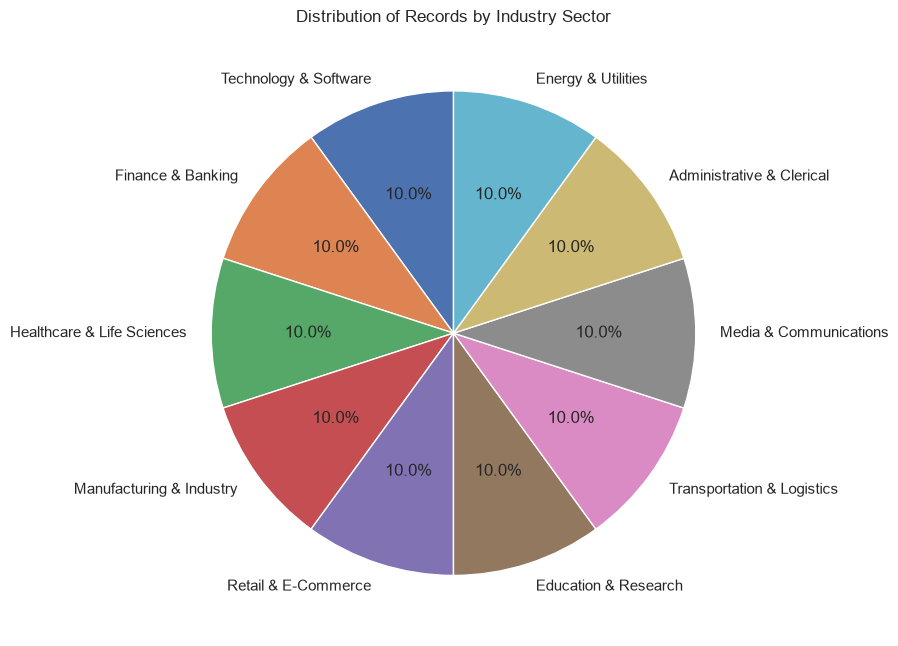

In [90]:
# Q16. What is the distribution of records across industry sectors?
# Visualize it using a pie chart.
sector_counts = df['industry_sector'].value_counts()
plt.figure(figsize=(9, 9))
plt.pie(sector_counts, labels=sector_counts.index, autopct='%1.1f%%', startangle=90)
plt.title("Distribution of Records by Industry Sector")
plt.tight_layout()
plt.show()

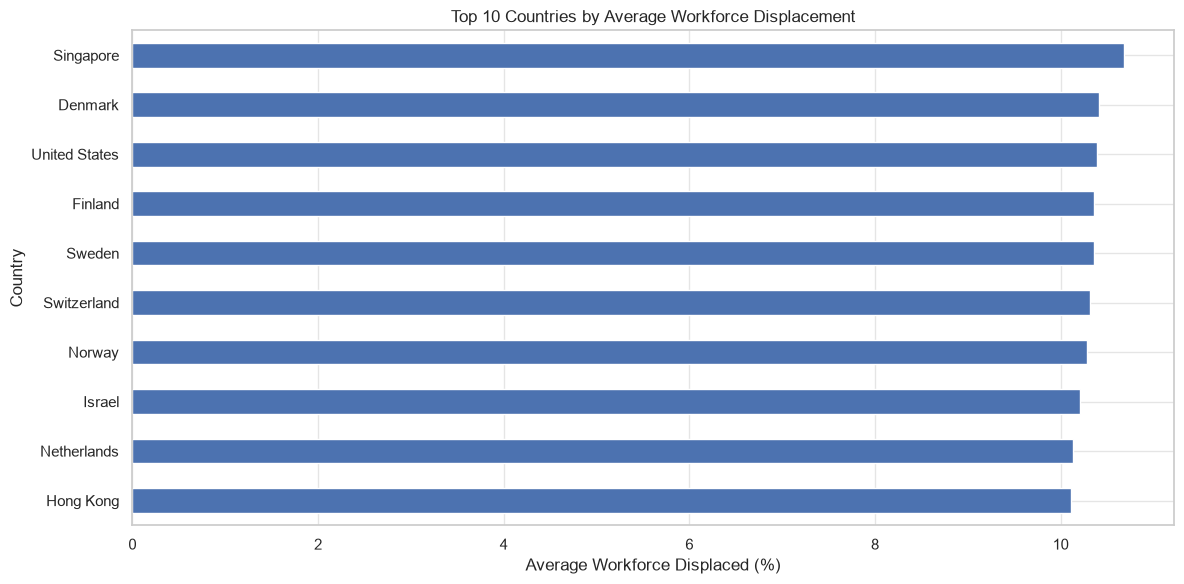

In [91]:
# Q17. Which 10 countries have the highest average workforce displacement?
# Visualize them using a bar chart.
top_countries = (
    df.groupby('country')['pct_sector_workforce_displaced']
      .mean()
      .sort_values(ascending=False)
      .head(10) * 100
)
plt.figure(figsize=(12, 6))
top_countries.sort_values().plot(kind='barh')
plt.title("Top 10 Countries by Average Workforce Displacement")
plt.xlabel("Average Workforce Displaced (%)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

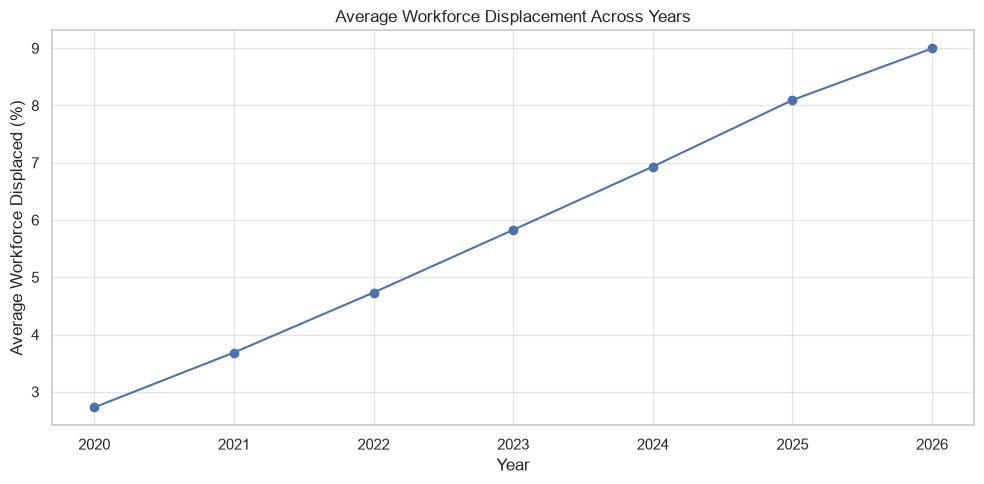

In [92]:
# Q18. How does average workforce displacement change across years?
# Visualize the trend using a line chart.
yearly = df.groupby('year')['pct_sector_workforce_displaced'].mean().sort_index() * 100
plt.figure(figsize=(10, 5))
plt.plot(yearly.index, yearly.values, marker='o')
plt.title("Average Workforce Displacement Across Years")
plt.xlabel("Year")
plt.ylabel("Average Workforce Displaced (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

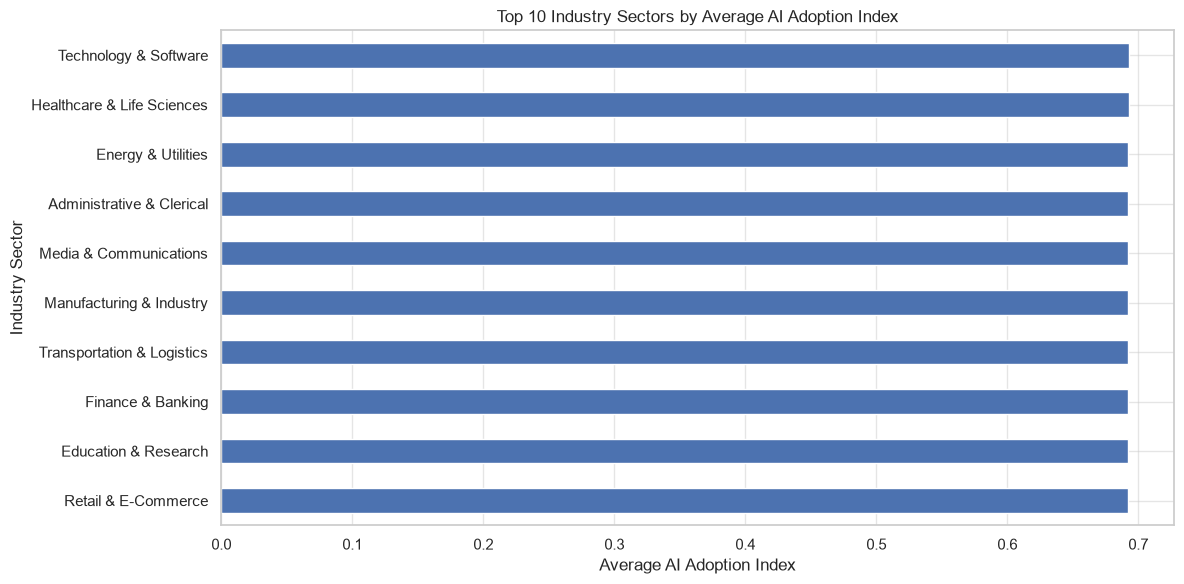

In [93]:
# Q19. Which industry sectors have the highest average AI adoption index?
# Visualize the top 10 using a bar chart.
top_sectors = (
    df.groupby('industry_sector')['ai_adoption_index']
      .mean()
      .sort_values(ascending=False)
      .head(10)
)
plt.figure(figsize=(12, 6))
top_sectors.sort_values().plot(kind='barh')
plt.title("Top 10 Industry Sectors by Average AI Adoption Index")
plt.xlabel("Average AI Adoption Index")
plt.ylabel("Industry Sector")
plt.tight_layout()
plt.show()

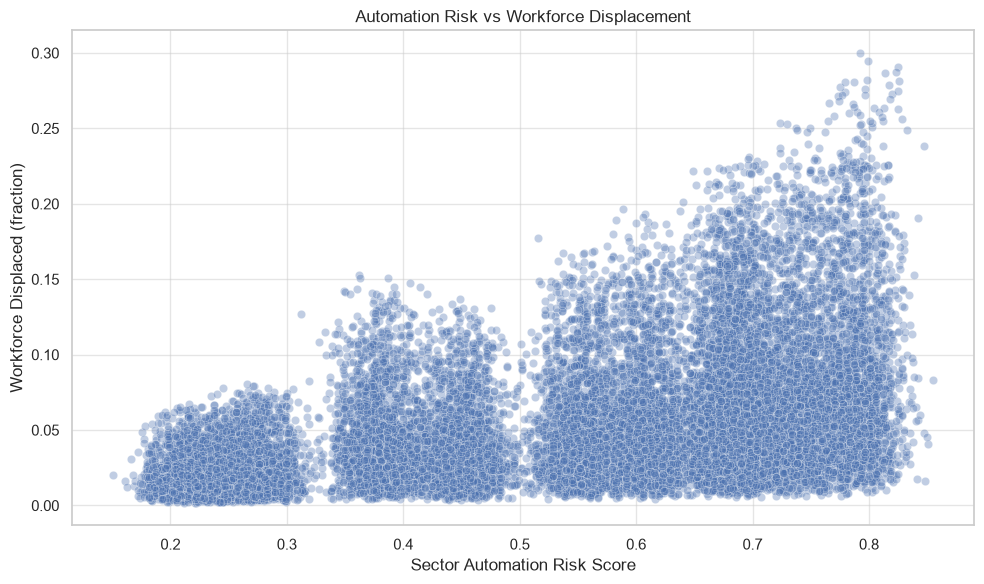

Correlation: 0.477


In [94]:
# Q20. What is the relationship between automation risk and workforce displacement?
# Visualize it using a scatter plot.
plot_data = df[['sector_automation_risk_score', 'pct_sector_workforce_displaced']].dropna()
plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_data, x='sector_automation_risk_score',
                y='pct_sector_workforce_displaced', alpha=0.35)
plt.title("Automation Risk vs Workforce Displacement")
plt.xlabel("Sector Automation Risk Score")
plt.ylabel("Workforce Displaced (fraction)")
plt.tight_layout()
plt.show()
print("Correlation:", round(plot_data['sector_automation_risk_score'].corr(
    plot_data['pct_sector_workforce_displaced']), 3))

Correlation: 0.516


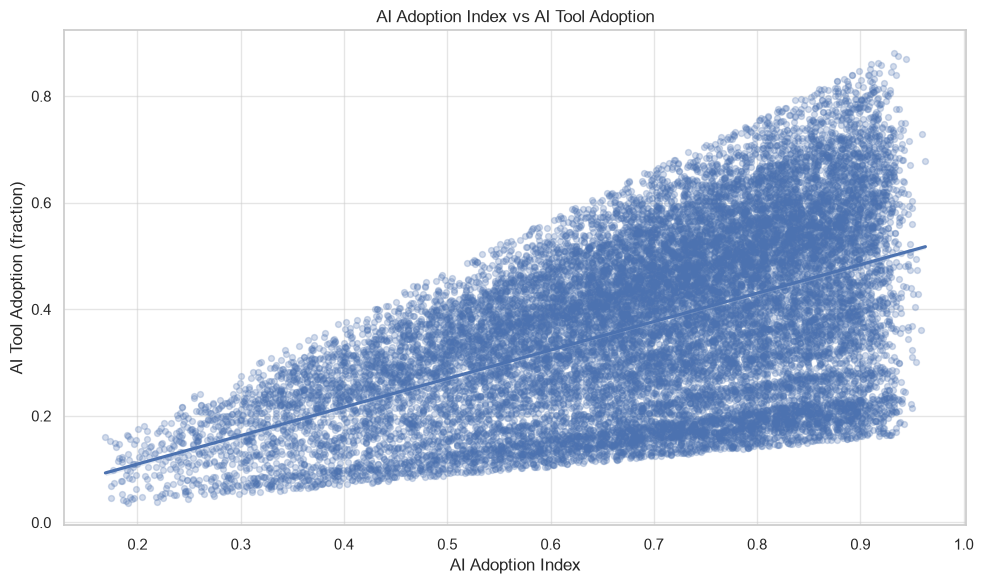

In [95]:
# Q21. Is there a relationship between AI adoption index and AI tool adoption percentage?
# Calculate the correlation and visualize it with a regression plot.
plot_data = df[['ai_adoption_index', 'ai_tool_adoption_pct']].dropna()
print("Correlation:", round(plot_data['ai_adoption_index'].corr(
    plot_data['ai_tool_adoption_pct']), 3))
plt.figure(figsize=(10, 6))
sns.regplot(data=plot_data, x='ai_adoption_index', y='ai_tool_adoption_pct',
            scatter_kws={'alpha': 0.25, 's': 18})
plt.title("AI Adoption Index vs AI Tool Adoption")
plt.xlabel("AI Adoption Index")
plt.ylabel("AI Tool Adoption (fraction)")
plt.tight_layout()
plt.show()

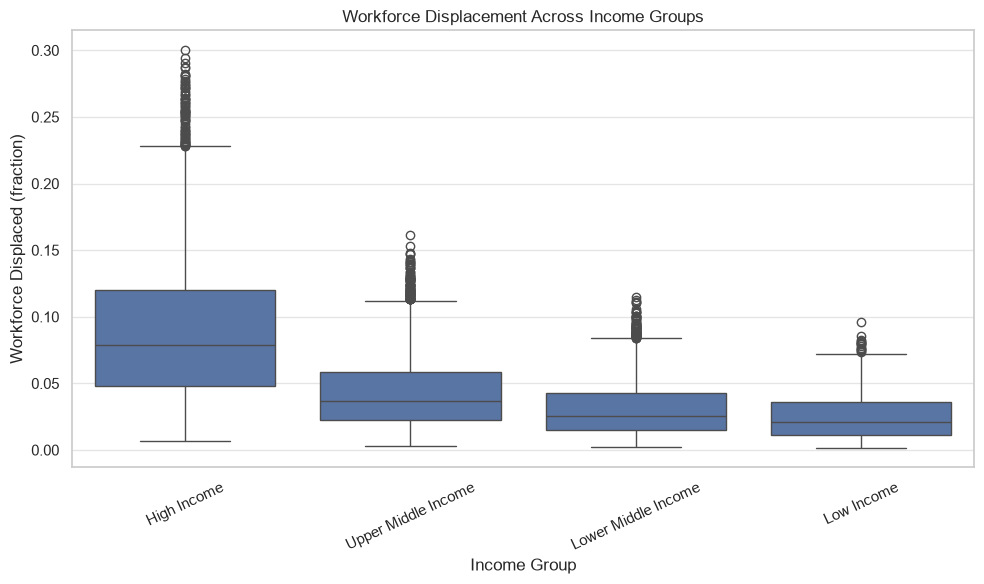

In [96]:
# Q22. How does workforce displacement vary across income groups?
# Use a boxplot.
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='income_group', y='pct_sector_workforce_displaced')
plt.title("Workforce Displacement Across Income Groups")
plt.xlabel("Income Group")
plt.ylabel("Workforce Displaced (fraction)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

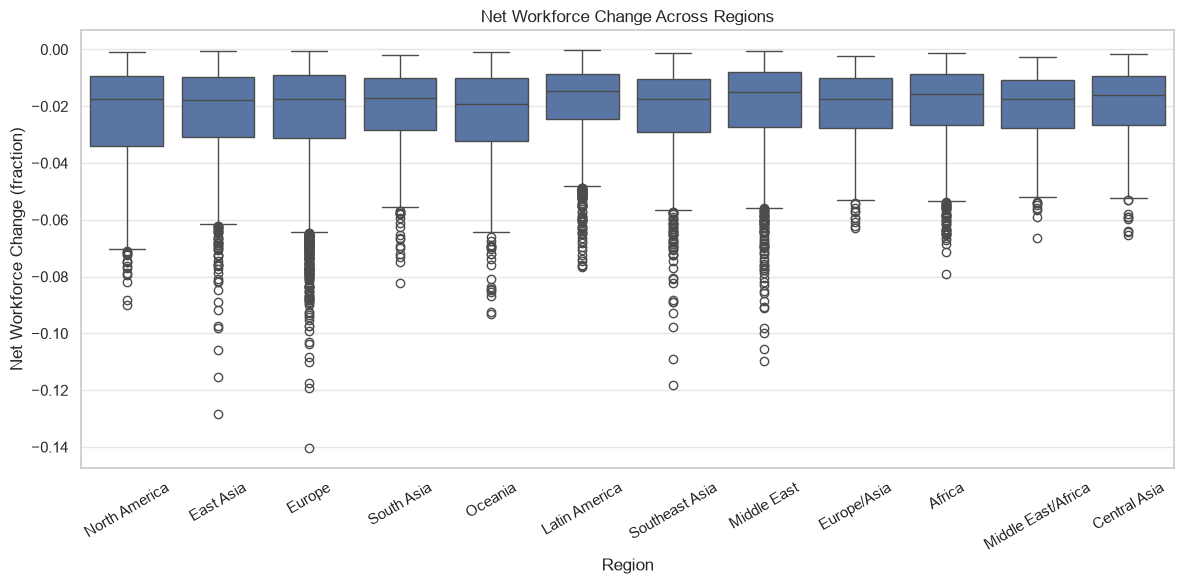

In [97]:
# Q23. How does net workforce change vary across regions?
# Use a boxplot.
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='region', y='net_workforce_change_pct')
plt.title("Net Workforce Change Across Regions")
plt.xlabel("Region")
plt.ylabel("Net Workforce Change (fraction)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

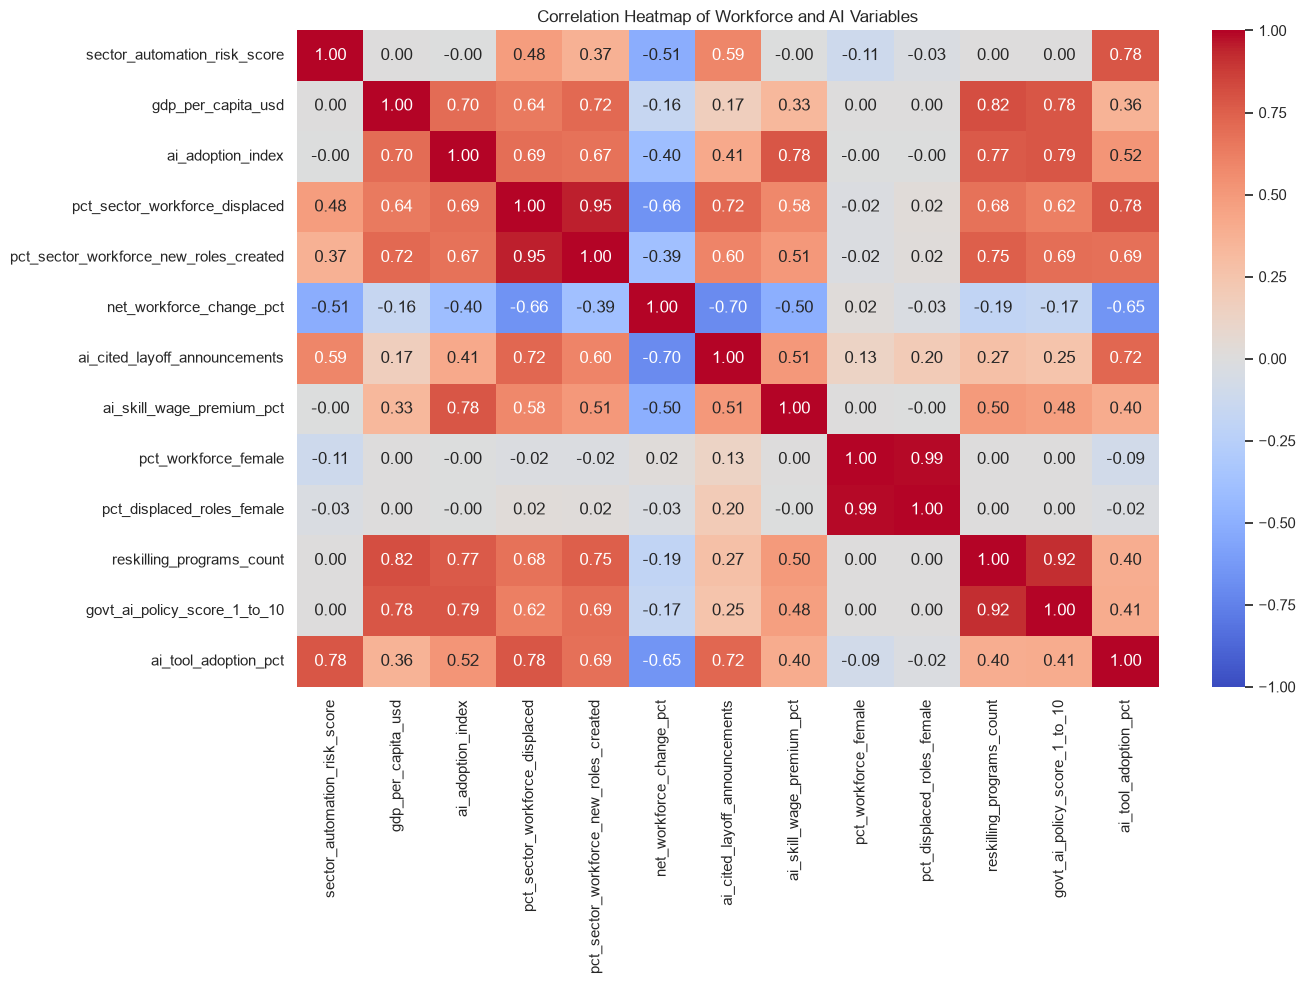

In [98]:
# Q24. What is the correlation between the major numerical variables?
# Create a correlation heatmap.
numeric_columns = [
    'sector_automation_risk_score',
    'gdp_per_capita_usd',
    'ai_adoption_index',
    'pct_sector_workforce_displaced',
    'pct_sector_workforce_new_roles_created',
    'net_workforce_change_pct',
    'ai_cited_layoff_announcements',
    'ai_skill_wage_premium_pct',
    'pct_workforce_female',
    'pct_displaced_roles_female',
    'reskilling_programs_count',
    'govt_ai_policy_score_1_to_10',
    'ai_tool_adoption_pct'
]
correlation_matrix = df[numeric_columns].corr()
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Workforce and AI Variables")
plt.tight_layout()
plt.show()

,pct_sector_workforce_displaced,pct_sector_workforce_new_roles_created,net_workforce_change_pct
period,,,
2020Q1,2.407550,1.600900,-0.806650
2020Q2,2.619950,1.717725,-0.902225
2020Q3,2.846875,1.846237,-1.000638
2020Q4,3.040450,2.006162,-1.034288
2021Q1,3.305075,2.171438,-1.133638


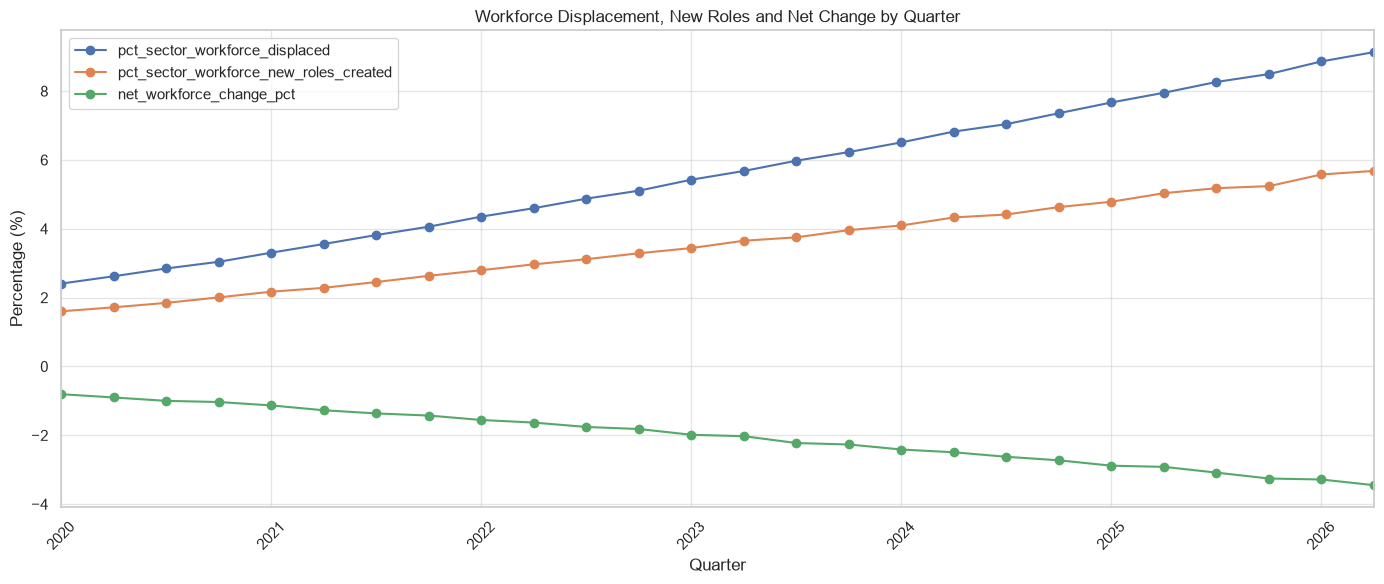

In [99]:
# Q25. How do workforce displacement, new-role creation, and net workforce change
# change over time by quarter?
df['period'] = pd.PeriodIndex(
    df['year'].astype(int).astype(str) + 'Q' + df['quarter'].astype(int).astype(str),
    freq='Q'
)
quarterly = (
    df.groupby('period')[[
        'pct_sector_workforce_displaced',
        'pct_sector_workforce_new_roles_created',
        'net_workforce_change_pct'
    ]].mean().sort_index() * 100
)
display(quarterly.head())
ax = quarterly.plot(figsize=(14, 6), marker='o')
ax.set_title("Workforce Displacement, New Roles and Net Change by Quarter")
ax.set_xlabel("Quarter")
ax.set_ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Correlation: 0.688


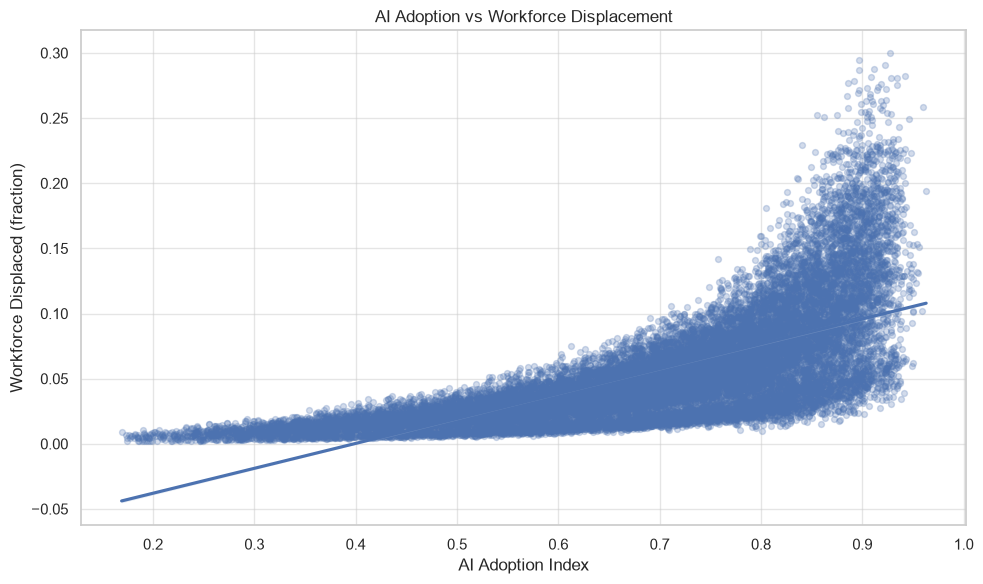

In [100]:
# Q26. Is higher AI adoption associated with higher workforce displacement?
plot_data = df[['ai_adoption_index', 'pct_sector_workforce_displaced']].dropna()
print("Correlation:", round(plot_data['ai_adoption_index'].corr(
    plot_data['pct_sector_workforce_displaced']), 3))
plt.figure(figsize=(10, 6))
sns.regplot(data=plot_data, x='ai_adoption_index',
            y='pct_sector_workforce_displaced',
            scatter_kws={'alpha': 0.25, 's': 18})
plt.title("AI Adoption vs Workforce Displacement")
plt.xlabel("AI Adoption Index")
plt.ylabel("Workforce Displaced (fraction)")
plt.tight_layout()
plt.show()

Correlation: -0.512


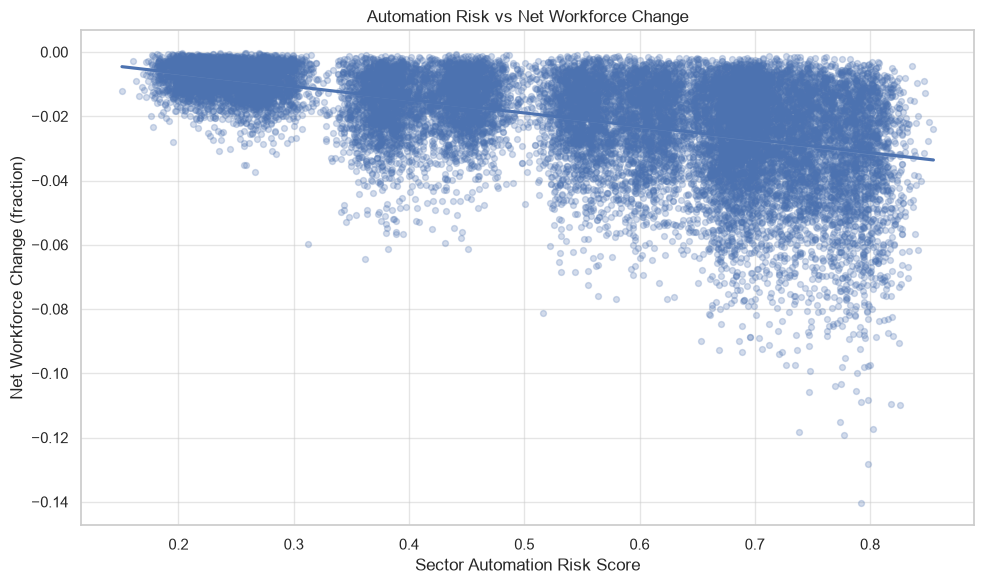

In [101]:
# Q27. Is a higher automation risk score associated with lower net workforce change?
plot_data = df[['sector_automation_risk_score', 'net_workforce_change_pct']].dropna()
print("Correlation:", round(plot_data['sector_automation_risk_score'].corr(
    plot_data['net_workforce_change_pct']), 3))
plt.figure(figsize=(10, 6))
sns.regplot(data=plot_data, x='sector_automation_risk_score',
            y='net_workforce_change_pct',
            scatter_kws={'alpha': 0.25, 's': 18})
plt.title("Automation Risk vs Net Workforce Change")
plt.xlabel("Sector Automation Risk Score")
plt.ylabel("Net Workforce Change (fraction)")
plt.tight_layout()
plt.show()

In [102]:
# Q28. Which industry sectors have the highest automation risk and lowest net workforce change?
industry_summary = (
    df.groupby('industry_sector')
      .agg(
          Average_Automation_Risk=('sector_automation_risk_score', 'mean'),
          Average_Net_Workforce_Change=('net_workforce_change_pct', 'mean'),
          Average_Displacement=('pct_sector_workforce_displaced', 'mean')
      )
      .sort_values('Average_Automation_Risk', ascending=False)
)
display(industry_summary)

,Average_Automation_Risk,Average_Net_Workforce_Change,Average_Displacement
industry_sector,,,
Administrative & Clerical,0.789742,-0.033699,0.092016
Manufacturing & Industry,0.739386,-0.029116,0.079422
Retail & E-Commerce,0.689231,-0.026680,0.073076
Transportation & Logistics,0.680379,-0.025166,0.068542
Finance & Banking,0.610245,-0.022037,0.060348
Media & Communications,0.550444,-0.019889,0.054123
Energy & Utilities,0.449988,-0.015178,0.041974
Technology & Software,0.379583,-0.016672,0.045995
Education & Research,0.270071,-0.009323,0.025171


In [103]:
# Q29. Which country-industry groups have both high workforce displacement
# and high AI-cited layoff announcements?
# "High" means above the dataset median for each measure.
grouped = (
    df.groupby(['country', 'industry_sector'])
      .agg(
          Average_Displacement=('pct_sector_workforce_displaced', 'mean'),
          Total_AI_Cited_Layoff_Announcements=('ai_cited_layoff_announcements', 'sum'),
          Average_Automation_Risk=('sector_automation_risk_score', 'mean')
      )
)
high_displacement = grouped['Average_Displacement'] > grouped['Average_Displacement'].median()
high_announcements = (
    grouped['Total_AI_Cited_Layoff_Announcements'] >
    grouped['Total_AI_Cited_Layoff_Announcements'].median()
)
result = grouped[high_displacement & high_announcements].sort_values(
    'Average_Displacement', ascending=False)
display(result.head(20))

,,Average_Displacement,Total_AI_Cited_Layoff_Announcements,Average_Automation_Risk
country,industry_sector,,,
Singapore,Administrative & Clerical,0.177242,7312,0.785269
Finland,Administrative & Clerical,0.175681,7485,0.790923
Sweden,Administrative & Clerical,0.175419,7240,0.793231
Netherlands,Administrative & Clerical,0.174427,6810,0.791077
Denmark,Administrative & Clerical,0.170369,6825,0.793808
Norway,Administrative & Clerical,0.170035,6764,0.788077
United States,Administrative & Clerical,0.169585,6988,0.790962
Hong Kong,Administrative & Clerical,0.168569,7667,0.785615
Austria,Administrative & Clerical,0.167650,6202,0.780846


Disruption_Category
Higher Disruption      10327
Moderate Disruption     9528
Lower Disruption         945
Name: Record Count, dtype: int64

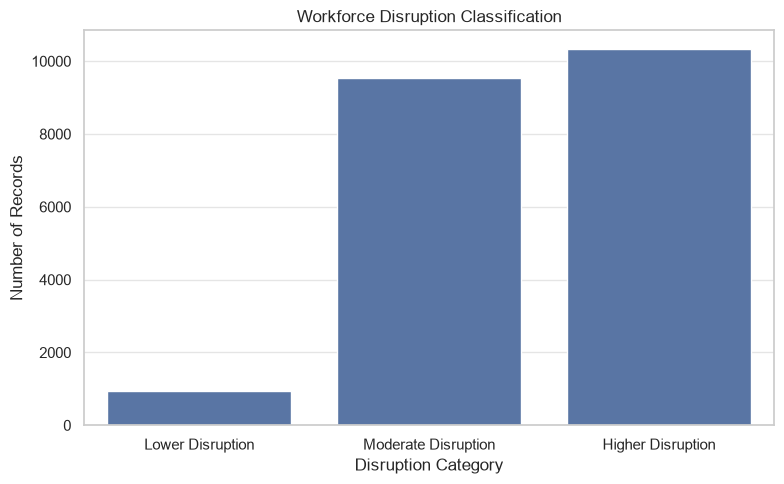

In [104]:
# Q30. Can we create an overall workforce disruption classification using
# displacement, automation risk, net workforce change, and new-role creation?
risk_df = df.copy()

# Create a simple transparent score: one point for each higher-risk signal.
risk_df['Disruption_Score'] = (
    (risk_df['pct_sector_workforce_displaced'] >
     risk_df['pct_sector_workforce_displaced'].median()).astype(int) +
    (risk_df['sector_automation_risk_score'] >
     risk_df['sector_automation_risk_score'].median()).astype(int) +
    (risk_df['net_workforce_change_pct'] < 0).astype(int) +
    (risk_df['pct_sector_workforce_new_roles_created'] <
     risk_df['pct_sector_workforce_new_roles_created'].median()).astype(int)
)

risk_df['Disruption_Category'] = pd.cut(
    risk_df['Disruption_Score'],
    bins=[-1, 1, 2, 4],
    labels=['Lower Disruption', 'Moderate Disruption', 'Higher Disruption']
)

display(risk_df['Disruption_Category'].value_counts().rename('Record Count'))

plt.figure(figsize=(8, 5))
sns.countplot(data=risk_df, x='Disruption_Category',
              order=['Lower Disruption', 'Moderate Disruption', 'Higher Disruption'])
plt.title("Workforce Disruption Classification")
plt.xlabel("Disruption Category")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# This is an exploratory rule-based classification, not a validated predictive model.

## Suggestions & Recommendations

1. **Monitor sectors with elevated automation risk.** Compare `sector_automation_risk_score` with workforce displacement and net workforce change. Prioritize further investigation where these indicators are consistently high.

2. **Plan reskilling alongside AI adoption.** Review `ai_adoption_index`, `ai_tool_adoption_pct`, and `reskilling_programs_count` together to identify sectors where adoption is high and reskilling activity may need attention.

3. **Track job creation as well as displacement.** Use `pct_sector_workforce_displaced`, `pct_sector_workforce_new_roles_created`, and `net_workforce_change_pct` together rather than interpreting displacement alone.

4. **Examine regional and income-group differences.** Compare patterns across `region` and `income_group` before proposing workforce policies; avoid assuming the same response fits every location.

5. **Consider inclusion in workforce planning.** Explore `pct_workforce_female` and `pct_displaced_roles_female` to assess whether displacement patterns differ in their representation of women.

6. **Use quarterly trends for planning.** Monitor changes from quarter to quarter and update the analysis when new data becomes available.

**Interpretation caution:** This dataset is described as synthetic. Recommendations are exploratory and should not be presented as proof of real-world causal relationships.